<div align="center">

# 📘 Logistic Regression — Complete Algorithm Handbook
### Theory • Intuition • Mathematics • Visuals • Evaluation • Interview Mastery

**Classification Algorithms Series · Part 1**

<span style="background:#dbeafe;color:#1d4ed8;padding:5px 10px;border-radius:12px"><b>FOUNDATIONS → MATH → PRACTICE</b></span>
<span style="background:#dcfce7;color:#166534;padding:5px 10px;border-radius:12px"><b>ONE Q&A PER CELL</b></span>
<span style="background:#fef3c7;color:#92400e;padding:5px 10px;border-radius:12px"><b>COLAB + JUPYTER READY</b></span>

</div>

<style>
.jp-RenderedHTMLCommon mjx-container[display="true"],
.jp-RenderedMarkdown mjx-container[display="true"],
.markdown-preview-view .katex-display {
  margin: 1.15rem 0 !important;
  padding: 0.9rem 1.1rem;
  overflow-x: auto;
  border-left: 4px solid #2563eb;
  border-radius: 8px;
  background: linear-gradient(90deg, rgba(37,99,235,.08), rgba(124,58,237,.04));
}
</style>

---

## How to study this notebook

1. Understand the problem Logistic Regression solves.
2. Learn the linear score, sigmoid, probability, odds, and log-odds.
3. Follow the loss-function and maximum-likelihood intuition.
4. Study regularization, thresholds, evaluation, assumptions, and limitations.
5. Run the visualization and implementation labs.
6. Practice the interview bank. **Each question and answer is in its own Markdown cell**, so you can collapse individual cells in Colab/Jupyter.

**Scope:** This is the first algorithm-specific notebook. It focuses on Logistic Regression; other classification algorithms will be covered separately. The interview bank is broad, but no finite list can literally contain every question an interviewer could invent.

## 1. 🎯 What problem does Logistic Regression solve?

**Logistic Regression is a supervised learning algorithm primarily used for classification.** Despite the word “regression” in its name, its standard classification form estimates the probability that an example belongs to a class.

Examples:
- Credit default: estimate the probability that a customer defaults.
- Churn: estimate the probability that a customer leaves.
- Fraud screening: rank transactions by estimated risk.
- Medical screening: estimate the probability of a defined outcome.
- Email filtering: estimate the probability that a message is spam.

For binary classification, the target is commonly encoded as $y \in \{0,1\}$. The model produces a probability $p=\Pr(Y=1\mid\mathbf{x})$. A decision threshold converts that probability into a class or action.

### The pipeline in one view

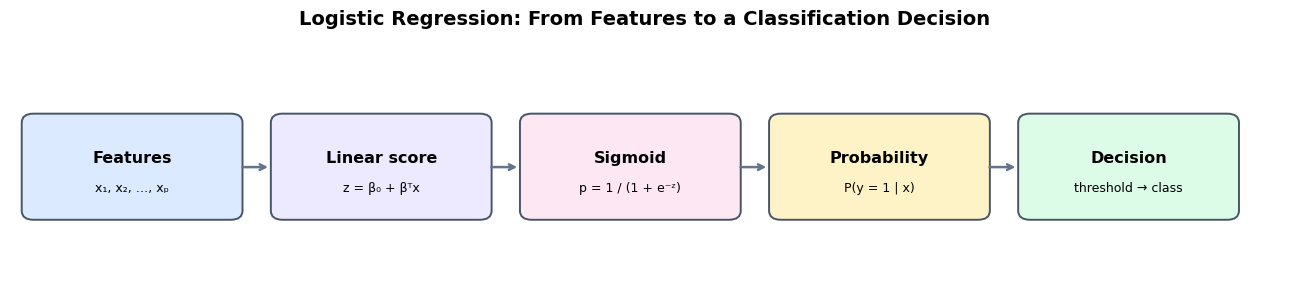

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 3.1))
ax.set_xlim(0, 13)
ax.set_ylim(0, 3.3)
ax.axis("off")

nodes = [
    ("Features", r"$x_1,\ x_2,\ \ldots,\ x_p$", "#DBEAFE"),
    ("Linear score", r"$z = \beta_0 + \mathbf{\beta}^{\mathsf{T}}\mathbf{x}$", "#EDE9FE"),
    ("Sigmoid", r"$p = \frac{1}{1 + e^{-z}}$", "#FCE7F3"),
    ("Probability", r"$\mathrm{P}(Y=1\mid\mathbf{x})$", "#FEF3C7"),
    ("Decision", "threshold → class", "#DCFCE7"),
]
xs = [0.2, 2.75, 5.3, 7.85, 10.4]
for i, ((title, sub, color), x) in enumerate(zip(nodes, xs)):
    box = FancyBboxPatch((x, 1.0), 2.1, 1.25, boxstyle="round,pad=0.08,rounding_size=0.12",
                         linewidth=1.4, edgecolor="#475569", facecolor=color)
    ax.add_patch(box)
    ax.text(x+1.05, 1.75, title, ha="center", va="center", fontsize=11.5, fontweight="bold")
    ax.text(x+1.05, 1.35, sub, ha="center", va="center", fontsize=9)
    if i < len(nodes)-1:
        ax.annotate("", xy=(xs[i+1]-0.08, 1.62), xytext=(x+2.15, 1.62),
                    arrowprops=dict(arrowstyle="->", lw=1.8, color="#64748B"))
ax.set_title("Logistic Regression: From Features to a Classification Decision", fontsize=14, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

### Key intuition

1. Calculate a weighted sum of the input features.
2. Transform that score into a value between 0 and 1 using the sigmoid function.
3. Interpret the output as an estimated probability, subject to model fit and calibration.
4. Apply a decision threshold that matches the use case and the costs of errors.

**Important:** the probability estimate and the final class decision are different outputs. The threshold is a decision policy; it is not inherently fixed at 0.5.

## 2. 🧮 Mathematical foundation

### 2.1 Linear score (logit input)

For $p$ features:

$$
z = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \cdots + \beta_p x_p
$$

In vector form:

$$
z = \beta_0 + \boldsymbol{\beta}^{\top}\mathbf{x}
$$

- $\mathbf{x}$: feature vector
- $\boldsymbol{\beta}$: learned coefficients
- $\beta_0$: intercept / bias
- $z$: linear score, also called the logit when interpreted as log-odds

The score $z$ can be any real number. It is **not yet a probability**.

### 2.2 Sigmoid / logistic function

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Therefore:

$$
\Pr(Y=1\mid\mathbf{x}) = p = \sigma(z)
$$

and for a binary target:

$$
\Pr(Y=0\mid\mathbf{x}) = 1 - p
$$

The sigmoid maps any real-valued score to the open interval $(0,1)$. Very large positive scores map near 1; very negative scores map near 0.

**Numerical intuition**
- $z=0 \Rightarrow p=0.5$
- $z>0 \Rightarrow p>0.5$
- $z<0 \Rightarrow p<0.5$

The function is smooth and differentiable, which makes gradient-based optimization practical.

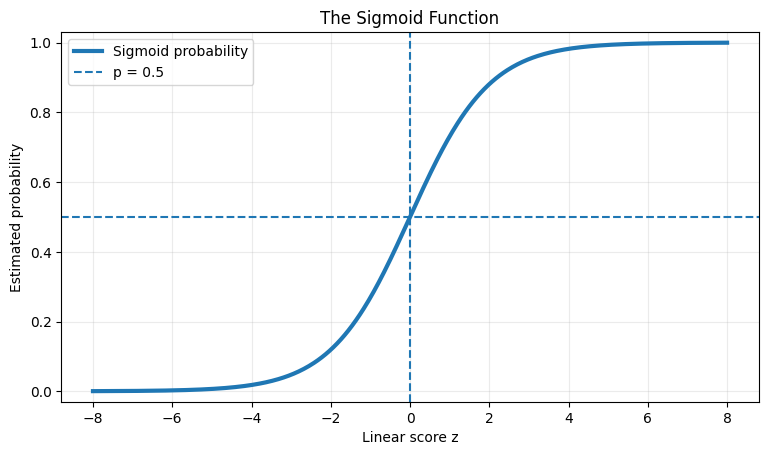

z=-4: probability=0.0180
z=-2: probability=0.1192
z= 0: probability=0.5000
z= 1: probability=0.7311
z= 2: probability=0.8808
z= 4: probability=0.9820


In [2]:
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-8, 8, 500)
sigmoid = 1 / (1 + np.exp(-z))

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(z, sigmoid, linewidth=3, label=r"$\sigma(z)=\frac{1}{1+e^{-z}}$")
ax.axhline(0.5, linestyle="--", linewidth=1.5, label=r"$p=0.5$")
ax.axvline(0, linestyle="--", linewidth=1.5)
ax.set_xlabel(r"Linear score $z$")
ax.set_ylabel(r"Estimated probability $p$")
ax.set_title("The Sigmoid Function")
ax.set_ylim(-0.03, 1.03)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

for value in [-4, -2, 0, 1, 2, 4]:
    probability = 1 / (1 + np.exp(-value))
    print(f"z={value:>2}: probability={probability:.4f}")

### 2.3 Odds and log-odds

Probability is $p\in(0,1)$. **Odds** compare the probability of an event with the probability of its complement:

$$
\operatorname{odds}(p) = \frac{p}{1-p}
$$

The **log-odds** (logit) are:

$$
\operatorname{logit}(p) = \log\!\left(\frac{p}{1-p}\right)
$$

Logistic Regression models these log-odds linearly:

$$
\log\left(\frac{p}{1-p}\right)
= \beta_0 + \boldsymbol{\beta}^{\top}\mathbf{x}
$$

Solving for probability gives the sigmoid equation.

**Coefficient interpretation:** holding other features fixed, increasing feature $x_j$ by one unit changes the log-odds by $\beta_j$. It multiplies the odds by $e^{\beta_j}$. This is an odds ratio—not a constant change in probability.

### 2.4 A small worked example

Suppose a fitted model has:

$$
z = -2 + 0.8x
$$

For an input $x=3$:

$$
z = -2 + 0.8(3) = 0.4
$$

$$
p = \sigma(0.4) = \frac{1}{1+e^{-0.4}} \approx 0.5987
$$

At a threshold of 0.5, the predicted class is 1. At a threshold of 0.65, the predicted class is 0. The underlying estimated probability did not change; only the decision rule changed.

For a coefficient of $0.8$, the odds multiplier for a one-unit increase in $x$ is $e^{0.8}\approx2.23$, holding other features fixed. It does **not** mean probability increases by 80 percentage points.

## 3. 📉 Why not use ordinary Linear Regression for classification?

Linear Regression predicts an unrestricted numeric value. If its output is treated as a probability, predictions can be below 0 or above 1, and its standard squared-error objective is not the usual likelihood-based objective for a Bernoulli target.

Logistic Regression:
- produces probabilities between 0 and 1;
- models log-odds linearly;
- uses a likelihood-based loss suited to binary outcomes;
- creates a linear decision boundary in the original feature space (unless features are transformed).

**Terminology note:** Logistic Regression is linear in its log-odds, not necessarily linear in probability.

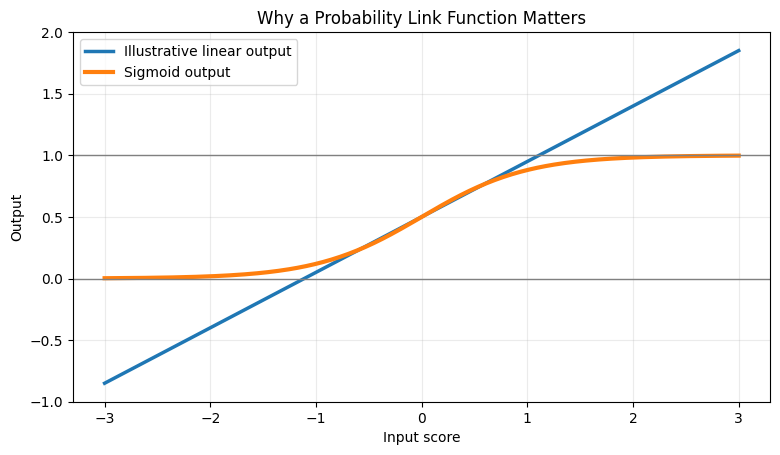

In [3]:
# Compare an unconstrained straight-line output with a sigmoid probability.
x = np.linspace(-3, 3, 300)
linear_output = 0.5 + 0.45*x
logistic_output = 1 / (1 + np.exp(-2*x))

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(x, linear_output, linewidth=2.5, label="Illustrative linear output")
ax.plot(x, logistic_output, linewidth=3, label="Sigmoid output")
ax.axhline(0, color="gray", linewidth=1)
ax.axhline(1, color="gray", linewidth=1)
ax.set_ylim(-1, 2)
ax.set_xlabel("Input score")
ax.set_ylabel("Output")
ax.set_title("Why a Probability Link Function Matters")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## 4. 🎯 Decision boundary and threshold

For binary classification, a common rule is:

$$
\widehat{y} =
\begin{cases}
1, & p \ge t,\\
0, & p < t.
\end{cases}
$$

where $t$ is the threshold. If $t=0.5$, then because sigmoid is increasing, $p\ge0.5$ corresponds to $z\ge0$.

With multiple features, the boundary at threshold 0.5 is:

$$
\beta_0 + \boldsymbol{\beta}^{\top}\mathbf{x}=0
$$

This is a line in 2D, a plane in 3D, and a hyperplane in higher dimensions. Nonlinear features (for example, polynomial or interaction terms) can create nonlinear boundaries in the original input space while retaining a linear model in the transformed features.

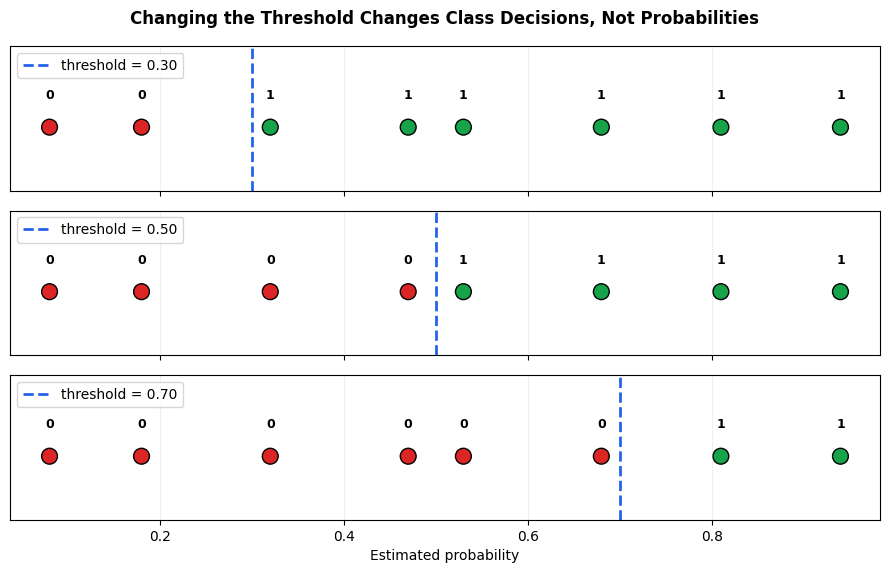

In [4]:

# Visualize how a fixed set of probabilities becomes class labels at different thresholds.
import numpy as np
import matplotlib.pyplot as plt

scores = np.array([0.08, 0.18, 0.32, 0.47, 0.53, 0.68, 0.81, 0.94])
thresholds = [0.30, 0.50, 0.70]

fig, axes = plt.subplots(len(thresholds), 1, figsize=(9, 5.8), sharex=True)
for ax, threshold in zip(axes, thresholds):
    predictions = (scores >= threshold).astype(int)
    colors = ["#16a34a" if v == 1 else "#dc2626" for v in predictions]
    ax.scatter(scores, np.zeros_like(scores), s=130, c=colors, edgecolor="black")
    ax.axvline(threshold, color="#2563eb", linestyle="--", linewidth=2,
               label=rf"threshold $t={threshold:.2f}$")
    for score, pred in zip(scores, predictions):
        ax.text(score, 0.08, str(pred), ha="center", fontsize=9, fontweight="bold")
    ax.set_ylim(-0.18, 0.23)
    ax.set_yticks([])
    ax.legend(loc="upper left")
    ax.grid(axis="x", alpha=0.2)
axes[-1].set_xlabel("Estimated probability")
fig.suptitle("Changing the Threshold Changes Class Decisions, Not Probabilities", fontweight="bold")
plt.tight_layout()
plt.show()


## 5. 🧾 Likelihood, log loss, and optimization

### 5.1 Bernoulli likelihood

For one labeled example $y_i\in\{0,1\}$ with predicted probability $p_i$:

$$
\Pr(Y_i=y_i\mid\mathbf{x}_i)=p_i^{y_i}(1-p_i)^{1-y_i}
$$

Assuming examples are conditionally independent under the model, the likelihood across $n$ examples is:

$$
\mathcal{L}(\boldsymbol{\beta})=\prod_{i=1}^{n}p_i^{y_i}(1-p_i)^{1-y_i}
$$

Maximum likelihood estimation (MLE) chooses parameters that maximize this likelihood. Because products can be numerically awkward, optimization usually minimizes the **negative log-likelihood**.

### 5.2 Binary cross-entropy / log loss

$$
\mathcal{J}(\boldsymbol{\beta})=-\frac{1}{n}\sum_{i=1}^{n}
\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right]
$$

- If $y_i=1$, the loss is $-\log(p_i)$.
- If $y_i=0$, the loss is $-\log(1-p_i)$.
- Confident correct predictions incur small loss.
- Confident incorrect predictions incur very large loss.

Log loss evaluates probability quality, not just whether the thresholded class was correct. Implementations clip probabilities or use numerically stable formulas to avoid taking logarithms of zero.

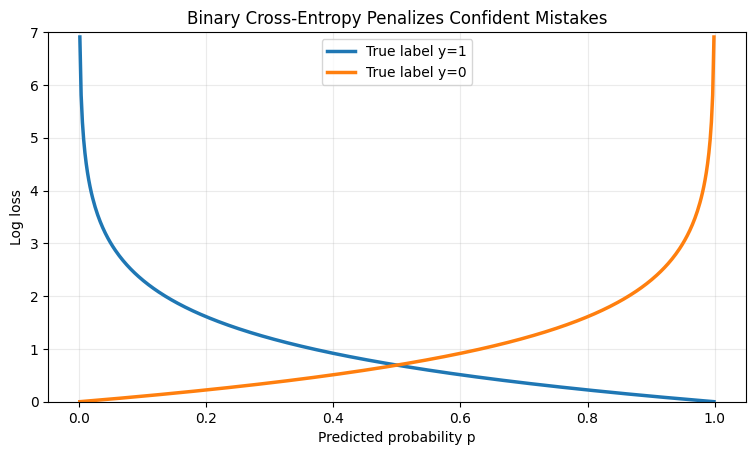

In [5]:
# Visualize binary log loss for a positive and a negative example.
p = np.linspace(0.001, 0.999, 500)
loss_positive = -np.log(p)       # y = 1
loss_negative = -np.log(1 - p)   # y = 0

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(p, loss_positive, linewidth=2.5, label=r"True label $y=1$")
ax.plot(p, loss_negative, linewidth=2.5, label=r"True label $y=0$")
ax.set_xlabel(r"Predicted probability $p$")
ax.set_ylabel("Log loss")
ax.set_title("Binary Cross-Entropy Penalizes Confident Mistakes")
ax.set_ylim(0, 7)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

### 5.3 Gradient and gradient descent intuition

For the average binary cross-entropy objective, without regularization, the gradient with respect to the coefficient vector is:

$$
\nabla_{\boldsymbol{\beta}}\mathcal{J}
=\frac{1}{n}\mathbf{X}^{\top}(\mathbf{p}-\mathbf{y})
$$

where $X$ is the design matrix (including an intercept column if the intercept is optimized in this representation), $p$ is the vector of predicted probabilities, and $y$ is the target vector.

The gradient tells us how the loss changes as parameters change. Gradient descent updates parameters in the direction opposite the gradient:

$$
\boldsymbol{\beta}^{(k+1)}
=\boldsymbol{\beta}^{(k)}-\eta\nabla\mathcal{J}\!\left(\boldsymbol{\beta}^{(k)}\right)
$$

Here $\eta$ is the learning rate. Too large a step can cause unstable optimization; too small a step can make learning slow. Scikit-learn's `LogisticRegression` commonly uses numerical optimization solvers rather than requiring the user to implement this update manually.

### 5.4 Regularization

Regularization penalizes excessive coefficient magnitude to reduce overfitting and improve stability.

**L2 penalty (ridge-style):**

$$
\mathcal{J}_{L_2}=\mathcal{J}+\lambda\sum_{j=1}^{p}\beta_j^2
$$

**L1 penalty (lasso-style):**

$$
\mathcal{J}_{L_1}=\mathcal{J}+\lambda\sum_{j=1}^{p}\lvert\beta_j\rvert
$$

The exact scaling and solver conventions depend on the implementation. In scikit-learn, regularization strength is commonly controlled by `C`, which is inversely related to regularization strength: smaller `C` means stronger regularization.

- **L2:** tends to shrink coefficients smoothly and can stabilize correlated predictors.
- **L1:** can drive some coefficients exactly to zero, creating a sparse model.
- **Elastic Net:** combines L1 and L2 penalties in supported configurations.

Do not compare coefficient magnitudes across features blindly if the feature scales differ.

## 6. 🧰 Assumptions and practical requirements

Logistic Regression does **not** require normally distributed predictors. The main practical considerations are:

1. **Binary target for standard binary Logistic Regression.** Multiclass variants are available.
2. **Correct specification of log-odds:** the logit should be adequately represented by the chosen features and transformations.
3. **Independent observations** for the usual likelihood-based inference assumptions; clustered or repeated observations may require a different design or uncertainty treatment.
4. **Limited problematic multicollinearity** if stable coefficient interpretation is important.
5. **Sufficient data and outcome variation** to estimate parameters reliably.
6. **No complete or quasi-complete separation** for stable finite maximum-likelihood estimates in the unregularized case.
7. **Appropriate preprocessing:** handle categorical values, missing data, and feature scaling where useful.
8. **Leakage-free evaluation:** split correctly and fit preprocessing only on training data.

Scaling is not a universal mathematical requirement for every solver, but it often helps optimization and makes regularization more comparable across features. Numeric and categorical feature preparation should be fit within a pipeline.

## 7. 🌍 Multiclass Logistic Regression

### One-vs-Rest (OvR)
Train one binary classifier per class, where each model separates its class from all other classes. Scores/probabilities are then combined according to the implementation.

### Multinomial / softmax
For $K$ classes, calculate one score per class:

$$
z_k = \beta_{k0}+\boldsymbol{\beta}_k^{\top}\mathbf{x}
$$

Convert scores to class probabilities using softmax:

$$
\Pr(Y=k\mid\mathbf{x})=\frac{e^{z_k}}{\displaystyle\sum_{j=1}^{K}e^{z_j}}
$$

The probabilities sum to 1 across classes. Softmax is the multiclass generalization of the logistic probability mapping in a common multinomial formulation.

In scikit-learn, supported solvers and the chosen configuration determine which multiclass behavior is used; consult the version-specific API when writing production code.

## 8. 📏 Evaluation: metrics and interpretation

### Confusion-matrix terms
- **TP:** positive example predicted positive
- **FP:** negative example predicted positive
- **TN:** negative example predicted negative
- **FN:** positive example predicted negative

$$
\begin{aligned}
\operatorname{Precision} &= \frac{TP}{TP+FP}, &
\operatorname{Recall} &= \frac{TP}{TP+FN}
\end{aligned}
$$

$$
\begin{aligned}
\operatorname{Specificity} &= \frac{TN}{TN+FP}, &
F_1 &= 2\,\frac{\operatorname{Precision}\cdot\operatorname{Recall}}{\operatorname{Precision}+\operatorname{Recall}}
\end{aligned}
$$

- **Accuracy:** overall fraction classified correctly; can mislead under severe class imbalance.
- **ROC-AUC:** evaluates ranking discrimination across thresholds.
- **PR curve / average precision:** focuses on precision-recall behavior, often useful with rare positives.
- **Log loss:** evaluates predicted probabilities.
- **Calibration:** checks whether probabilities match observed event frequencies.
- **Balanced accuracy:** averages recall across classes in binary classification.
- **Cost-based metrics:** useful when false positives and false negatives have different business costs.

Choose metrics from the decision problem, not because a metric is conventional.

In [6]:
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_auc_score,
    average_precision_score, log_loss, brier_score_loss
)

y_true = np.array([0, 0, 0, 1, 1, 1, 1, 0, 1, 0])
y_prob = np.array([0.08, 0.24, 0.31, 0.72, 0.65, 0.91, 0.48, 0.40, 0.84, 0.12])
threshold = 0.5
y_pred = (y_prob >= threshold).astype(int)

print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(y_true, y_pred))
print("\nClassification report:")
print(classification_report(y_true, y_pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 3))
print("Average precision:", round(average_precision_score(y_true, y_prob), 3))
print("Log loss:", round(log_loss(y_true, y_prob), 3))
print("Brier score:", round(brier_score_loss(y_true, y_prob), 3))

Confusion matrix (rows=true, columns=predicted):
[[5 0]
 [1 4]]

Classification report:
              precision    recall  f1-score   support

           0       0.83      1.00      0.91         5
           1       1.00      0.80      0.89         5

    accuracy                           0.90        10
   macro avg       0.92      0.90      0.90        10
weighted avg       0.92      0.90      0.90        10

ROC-AUC: 1.0
Average precision: 1.0
Log loss: 0.313
Brier score: 0.084


## 9. 🧪 Practical implementation with scikit-learn

This example uses a synthetic, reproducible dataset so it runs without downloading files. The aim is to demonstrate the correct workflow, not to claim that synthetic results represent a real business.

**Workflow**
1. Split train and test data before fitting learned preprocessing.
2. Scale numeric features inside a pipeline.
3. Fit Logistic Regression on training data only.
4. Evaluate probabilities and thresholded classes separately.
5. Inspect coefficients with feature names.
6. Tune thresholds and hyperparameters on validation data or cross-validation—not on the final test set.

In [7]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, log_loss

# Generate a deterministic binary classification dataset.
X, y = make_classification(
    n_samples=1800,
    n_features=8,
    n_informative=5,
    n_redundant=2,
    weights=[0.72, 0.28],
    class_sep=1.0,
    random_state=42,
)

feature_names = [f"feature_{i}" for i in range(X.shape[1])]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

# Scaling is fit only on training data because it is inside the pipeline.
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(C=1.0, max_iter=2000, random_state=42)),
])
model.fit(X_train, y_train)

probabilities = model.predict_proba(X_test)[:, 1]
predictions = (probabilities >= 0.5).astype(int)

print(f"Accuracy:  {accuracy_score(y_test, predictions):.3f}")
print(f"Precision: {precision_score(y_test, predictions, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, predictions, zero_division=0):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, probabilities):.3f}")
print(f"Log loss:  {log_loss(y_test, probabilities):.3f}")

Accuracy:  0.878
Precision: 0.861
Recall:    0.680
ROC-AUC:   0.918
Log loss:  0.330


In [8]:
# Inspect fitted coefficients after standardization.
fitted_logreg = model.named_steps["logreg"]
coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": fitted_logreg.coef_[0],
    "odds_ratio_per_scaled_unit": np.exp(fitted_logreg.coef_[0]),
}).sort_values("coefficient", key=np.abs, ascending=False)

display(coefficient_table)
print("Intercept:", fitted_logreg.intercept_[0])

,feature,coefficient,odds_ratio_per_scaled_unit
1,feature_1,-1.764582,0.171258
4,feature_4,1.724750,5.611120
5,feature_5,-1.315344,0.268382
0,feature_0,0.783677,2.189507
3,feature_3,-0.474842,0.621983
6,feature_6,0.311666,1.365699
7,feature_7,-0.077870,0.925085
2,feature_2,-0.029388,0.971040


Intercept: -1.985005089864063


## 10. 🧠 Coefficients: interpretation and cautions

- A positive coefficient means a larger feature value increases the modeled log-odds of class 1, holding other modeled features constant.
- A negative coefficient decreases the modeled log-odds.
- $e^{\beta_j}$ is the multiplicative change in odds for a one-unit increase in feature $j$, holding other features constant.
- A coefficient is not a probability change.
- If features are standardized, the coefficient corresponds to a one-standard-deviation increase (under the scaler's convention), not a one-unit increase in the original feature.
- With correlated predictors, coefficients can be unstable or their signs can be counterintuitive.
- A predictive association is not automatically causal.
- Interpreting coefficients for one-hot encoded categories requires knowing the reference category and encoding scheme.

## 11. ⚖️ Strengths, limitations, and when to use it

### Strengths
- Fast and strong baseline for many classification problems.
- Naturally outputs class probabilities.
- Coefficients can be interpreted under suitable feature design.
- Works well with sparse high-dimensional inputs, such as text features, in many settings.
- Regularization helps control complexity.
- Easy to package and deploy.

### Limitations
- A linear boundary in the chosen feature space may underfit complex nonlinear relationships.
- Coefficient interpretation can be misleading with correlated features, poor scaling, or omitted interactions.
- Probability calibration is not guaranteed just because output is called a probability.
- Separation, small samples, rare events, and label noise can complicate estimation.
- Outliers and misspecified relationships can affect results.
- The default 0.5 threshold may not match business costs or class imbalance.

### Consider it when
- You need a clear baseline and reasonably interpretable coefficients.
- The relationship is adequately represented by linear log-odds in engineered features.
- Probability estimates and ranking are useful.
- Latency and deployment simplicity matter.

### Consider another approach or richer features when
- The decision boundary is strongly nonlinear and feature engineering is insufficient.
- Interactions and complex patterns dominate.
- The data modality or scale suggests another model family is more suitable.
- Operational evaluation shows unacceptable errors.

## 12. 🎤 Interview bank — one question and answer per cell

Each question below is a separate Markdown cell with its answer immediately below it. Use the cell collapse control to study one at a time. Questions range from beginner to advanced, mathematics, assumptions, evaluation, debugging, and real-world scenarios.

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q1. Why is Logistic Regression called regression if it is used for classification?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It models a continuous linear quantity—the log-odds—as a function of features, then maps that score to class probability. The usual output is used for classification, even though the modeled quantity is a regression on the log-odds scale.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q2. What is Logistic Regression?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A supervised classification method that models the log-odds of an outcome as a linear combination of features and transforms that score into a probability using the logistic function.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q3. What problem does binary Logistic Regression solve?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It estimates the probability of one of two target outcomes, such as churn versus no churn, and supports decisions based on a chosen threshold or cost policy.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q4. What is the difference between Linear and Logistic Regression?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Linear Regression predicts an unrestricted numeric value and commonly minimizes squared error. Logistic Regression predicts a probability through a link function and commonly minimizes binary cross-entropy/negative log-likelihood.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q5. What is the logistic or sigmoid function?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
The logistic function is

$$\displaystyle \sigma(z)=\frac{1}{1+e^{-z}}.$$

It maps every real-valued score to a value strictly between 0 and 1.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q6. Why does Logistic Regression use sigmoid?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It maps the linear score to a valid binary probability and provides a smooth differentiable function suitable for likelihood-based optimization.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q7. What is the linear predictor?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
The linear predictor is

$$\displaystyle z=\beta_0+\boldsymbol{\beta}^{\top}\mathbf{x}.$$

It is a weighted sum of input features plus an intercept—not a probability.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q8. What is a logit?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
The logit is the log-odds:

$$\displaystyle \operatorname{logit}(p)=\log\!\left(\frac{p}{1-p}\right).$$

In Logistic Regression, this quantity is modeled as a linear function of the features.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q9. What are odds?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Odds compare an event with its complement:

$$\displaystyle \operatorname{odds}(p)=\frac{p}{1-p}.$$
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q10. What is the difference between probability and odds?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Probability lies between 0 and 1; odds range from 0 to infinity. For $p=0.8$, the odds are $\dfrac{0.8}{0.2}=4$.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q11. What are log-odds?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
The natural logarithm of odds. They can range over all real numbers, which makes them convenient to model with a linear score.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q12. How do you derive the sigmoid from the logit equation?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Start with the logit equation and rearrange:

$$
\begin{aligned}
\log\!\left(\frac{p}{1-p}\right)&=z \\
\frac{p}{1-p}&=e^z \\
p&=\frac{e^z}{1+e^z}=\frac{1}{1+e^{-z}}.
\end{aligned}
$$
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q13. What does the intercept represent?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
The baseline log-odds when all modeled features equal zero. Its practical meaning depends on feature coding and centering.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q14. What does a positive coefficient mean?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Holding other features fixed, a one-unit increase in that feature increases modeled log-odds of class 1. It multiplies odds by $e^{\beta_j}$, not probability by a fixed amount.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q15. What does a negative coefficient mean?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Holding other features fixed, a one-unit increase in the feature decreases modeled log-odds and multiplies odds by $e^{\beta_j}$, which is below 1.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q16. How do you interpret a coefficient using an odds ratio?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Exponentiate the coefficient:

$$\displaystyle \mathrm{OR}_j=e^{\beta_j}.$$

A one-unit increase multiplies the odds by $\mathrm{OR}_j$, holding other features constant. The effect on probability depends on the starting probability.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q17. If $\beta_j=0.7$, what is the odds ratio?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
$e^{0.7}\approx2.01$. A one-unit increase multiplies odds by about 2.01, holding other features constant; it does not double probability.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q18. If $\beta_j=-0.5$, what is the odds ratio?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
$e^{-0.5}\approx0.607$. The odds become about 60.7% of their prior value per unit increase, holding other features constant.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q19. Does a coefficient of 2 mean probability rises by 200%?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
No. It means log-odds increase by 2 per unit. Odds multiply by $e^2\approx7.39$; probability changes nonlinearly depending on the starting point.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q20. Why is Logistic Regression linear?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It is linear in the log-odds with respect to the modeled features. Its probability curve is nonlinear because the sigmoid transforms the score.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q21. Is the decision boundary linear?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
At a fixed probability threshold, the boundary is linear in the feature space used by the model. Feature transformations and interactions can make it nonlinear in the original input space.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q22. What is the decision threshold?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A cutoff on the predicted probability or score used to select a class or action. It is a decision policy, not a learned coefficient by default.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q23. Why is 0.5 a common threshold?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
For calibrated binary probabilities and equal misclassification costs with suitable assumptions, 0.5 is a natural default. Real costs, class prevalence, or operational constraints may call for another threshold.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q24. How does lowering the threshold affect precision and recall?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Usually it predicts more positives, increasing recall while often reducing precision; the exact trade-off depends on the score distribution.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q25. How does raising the threshold affect precision and recall?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Usually fewer cases are labeled positive, which often increases precision and decreases recall. It is not guaranteed for every dataset but is the typical trade-off.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q26. Can Logistic Regression return probabilities?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Yes. In scikit-learn, `predict_proba()` returns estimated class probabilities, subject to the fitted model and preprocessing.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q27. What is the difference between `predict()` and `predict_proba()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`predict_proba()` returns class probability estimates; `predict()` returns class labels using the estimator's decision rule, typically associated with a default threshold for binary classification.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q28. What loss does Logistic Regression minimize?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Common binary Logistic Regression implementations minimize negative log-likelihood, equivalent to binary cross-entropy, with regularization depending on the configuration.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q29. What is binary cross-entropy?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
For one binary example, the loss is

$$\displaystyle \ell(y,p)=-\left[y\log(p)+(1-y)\log(1-p)\right].$$

It is averaged or summed across examples according to convention and penalizes confident incorrect probabilities heavily.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q30. Why not use mean squared error for standard Logistic Regression?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
MSE can be used in some custom setups, but negative log-likelihood/cross-entropy matches the Bernoulli probability model and yields a well-motivated convex objective for the standard linear-logit formulation.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q31. What is maximum likelihood estimation?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A parameter-estimation principle that chooses parameters making the observed labels most probable under the model. For Logistic Regression this leads to minimizing negative log-likelihood.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q32. What is the likelihood for a binary target?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
For one example, the Bernoulli likelihood contribution is

$$\displaystyle p^y(1-p)^{1-y}.$$

Under conditional independence, the full likelihood is the product over observations.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q33. Why take the logarithm of likelihood?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It turns products into sums, simplifies derivatives, and is numerically more stable. Maximizing log-likelihood is equivalent to maximizing likelihood.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q34. What is the gradient of logistic loss?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
For average unregularized binary cross-entropy, the coefficient gradient is

$$\displaystyle \nabla_{\boldsymbol{\beta}}\mathcal{J}=\frac{1}{n}\mathbf{X}^{\top}(\mathbf{p}-\mathbf{y}).$$

Intercept handling depends on the design-matrix convention.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q35. What is gradient descent?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
An iterative optimization method that updates parameters opposite the loss gradient, using a learning rate to control step size.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q36. Does scikit-learn LogisticRegression require manually coding gradient descent?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
No. It uses supported numerical optimization solvers. The exact solver and options depend on penalty, data, and library version.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q37. What is regularization?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A penalty on coefficient complexity that can reduce overfitting and stabilize estimates. Common choices include L1, L2, and supported Elastic Net configurations.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q38. What is L1 regularization?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A penalty proportional to the sum of absolute coefficient values. It can produce sparse solutions with some coefficients exactly zero.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q39. What is L2 regularization?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A penalty proportional to the sum of squared coefficients. It tends to shrink coefficients smoothly rather than setting many exactly to zero.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q40. What is Elastic Net?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A combination of L1 and L2 penalties, offering a compromise between sparsity and smooth shrinkage in supported implementations.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q41. What does `C` mean in scikit-learn LogisticRegression?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
C is the inverse of regularization strength: smaller C means stronger regularization; larger C means weaker regularization.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q42. What happens if regularization is too strong?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Coefficients may be shrunk too much, leading to underfitting and poor predictive performance.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q43. What happens if regularization is too weak?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
The model may fit noise or unstable effects, especially with many features, correlated predictors, or limited data.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q44. Why scale features for Logistic Regression?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Scaling can improve numerical optimization and makes regularization affect coefficients more comparably across feature units. It is especially useful when feature scales vary substantially.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q45. Is feature scaling mathematically mandatory?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Not universally. Some solvers can fit unscaled data, but scaling often improves optimization and regularization behavior. Fit the scaler on training data only.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q46. Does Logistic Regression require normally distributed features?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
No. The predictors do not need to be normally distributed for standard Logistic Regression.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q47. Does Logistic Regression require features to be uncorrelated?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
No, but strong multicollinearity can make coefficient estimates unstable and interpretation difficult. Predictive performance may still be acceptable.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q48. What assumptions matter for Logistic Regression?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A suitable linear specification of log-odds, appropriate target definition, independent observations for standard inference assumptions, no severe separation for finite unregularized estimates, and adequate data. Distributional normality of predictors is not required.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q49. What is multicollinearity?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Strong dependence among predictors. It can inflate coefficient uncertainty, make signs/magnitudes unstable, and complicate interpretation.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q50. What is complete separation?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A condition where features perfectly separate the classes. The unregularized maximum-likelihood coefficients may diverge rather than converge to finite values.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q51. What is quasi-complete separation?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A related situation where some observations are separated perfectly while others lie on a boundary; it can also cause unstable or unbounded unregularized estimates.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q52. How can regularization help with separation?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Penalization can constrain coefficient magnitude and yield more stable fitted parameters, though small-sample and separation issues still need careful evaluation.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q53. What is class imbalance?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A target distribution where one class is much less common. Accuracy may be misleading, and metrics, thresholds, and class weighting may need special consideration.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q54. How can Logistic Regression address class imbalance?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use appropriate metrics, tune the threshold on validation data, consider class weights or resampling within training folds, and verify probability calibration and deployment prevalence.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q55. Does `class_weight='balanced'` solve all imbalance problems?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
No. It changes the training loss weighting based on class frequencies, but does not guarantee improved business utility, calibrated probabilities, or good generalization.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q56. Which metrics are useful for Logistic Regression?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Accuracy, precision, recall, F1, specificity, ROC-AUC, precision-recall summaries, log loss, Brier score, and calibration diagnostics, selected according to the decision objective.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q57. When is accuracy misleading?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
When classes are imbalanced or error costs differ. A model can achieve high accuracy by predicting the majority class while missing important positives.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q58. ROC-AUC versus average precision?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
ROC-AUC summarizes ranking across false-positive and true-positive rates. Average precision summarizes precision-recall behavior and is often informative for rare positive classes.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q59. What is calibration?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
The property that predicted probabilities agree with observed event frequencies across comparable cases. Ranking ability and calibration are different properties.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q60. Does Logistic Regression always produce calibrated probabilities?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
No. Its probabilistic form can be well calibrated when the model is appropriately specified and trained, but misspecification, regularization, shift, and finite data can cause miscalibration.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q61. What is the Brier score?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
The mean squared difference between predicted probability and binary outcome. Lower is better; it reflects both calibration and discrimination-related aspects.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q62. What is log loss useful for?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Evaluating probability estimates while penalizing confident incorrect predictions. It distinguishes probability quality that a hard-label accuracy metric can hide.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q63. What is multiclass Logistic Regression?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A generalization to more than two classes, commonly using one-vs-rest classifiers or a multinomial model with softmax probabilities.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q64. What is One-vs-Rest?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Train one binary classifier per class, treating that class as positive and all other classes as negative, then combine the scores or probabilities.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q65. What is softmax?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
For class scores $z_k$, softmax assigns

$$\displaystyle p_k=\frac{e^{z_k}}{\sum_{j=1}^{K}e^{z_j}},\qquad k=1,\ldots,K.$$

The resulting probabilities are nonnegative and sum to one.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q66. What is the difference between sigmoid and softmax?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Sigmoid is the common probability link for a binary outcome; softmax normalizes multiple class scores into a distribution across mutually exclusive classes.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q67. Can Logistic Regression handle categorical features?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Yes, after appropriate encoding, commonly one-hot encoding for nominal categories. Encoding should be fit within a training pipeline and unknown categories need an explicit policy.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q68. Why avoid arbitrary integer encoding of nominal categories?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It can impose a false numeric order and distance between categories. One-hot or other justified encodings are often safer for nominal variables.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q69. Can Logistic Regression handle missing values directly in scikit-learn?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
The standard `LogisticRegression` estimator generally expects finite numeric inputs. Impute or otherwise handle missing values in a preprocessing pipeline.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q70. How do you avoid preprocessing leakage?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Split first and put learned preprocessing—imputation, scaling, encoding, selection—inside a pipeline fit only on training folds.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q71. Why use a Pipeline?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It ensures transformations and the estimator are fitted and applied consistently, supports leakage-safe cross-validation, and simplifies deployment.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q72. How do you interpret coefficients after standardization?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A coefficient corresponds to a one-unit increase in the scaled feature, often one standard deviation for standard scaling, holding other scaled features constant.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q73. Can a coefficient be interpreted causally?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
No, not by itself. It describes a conditional association under the model; causal claims require an appropriate design and assumptions.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q74. What is the effect of adding an interaction term?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It allows the effect associated with one feature to vary with another feature, changing the log-odds by an interaction-dependent amount.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q75. How can Logistic Regression model nonlinear relationships?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Engineer nonlinear features such as splines, polynomial terms, bins, or interactions. The model remains linear in the transformed feature coefficients.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q76. What is a decision boundary in two dimensions?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
At threshold $t=0.5$, the boundary is the line

$$\displaystyle \beta_0+\beta_1x_1+\beta_2x_2=0.$$

At other thresholds, the score boundary shifts to the logit of the threshold.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q77. How does threshold t affect the score boundary?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
For probability threshold $t$, the score boundary is

$$\displaystyle \beta_0+\boldsymbol{\beta}^{\top}\mathbf{x}=\log\!\left(\frac{t}{1-t}\right).$$

At $t=0.5$, the right-hand side is zero.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q78. Why can two thresholds produce different confusion matrices for the same model?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Changing the threshold changes which probabilities are labeled positive, changing TP, FP, TN, and FN even though the fitted coefficients and probabilities remain the same.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q79. How should you choose a threshold in a business application?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use validation predictions and the costs or constraints of decisions—such as false-negative cost, review capacity, or required recall. Keep the final test set untouched.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q80. How do you select hyperparameters?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use cross-validation or a validation set to compare settings such as C, penalty, and solver where compatible. Keep preprocessing inside the validation workflow.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q81. What is the difference between model selection and final evaluation?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Model selection uses training/validation evidence to choose the approach; final evaluation uses a held-out test set after decisions are frozen.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q82. What is underfitting in Logistic Regression?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
The chosen features and linear-logit structure fail to capture relevant patterns, producing poor training and held-out performance.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q83. What is overfitting in Logistic Regression?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
The fitted coefficients capture noise or unstable patterns, often due to too many features, weak regularization, leakage, or limited data.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q84. How can you diagnose poor Logistic Regression performance?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Check data quality, target definition, split design, class balance, leakage, feature encoding, calibration, threshold, residual/error slices, coefficient stability, and whether the logit specification is adequate.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q85. What does a large coefficient indicate?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A large log-odds effect per feature unit, but its interpretation depends on scaling, encoding, regularization, correlation, and data support. Magnitude alone does not prove importance.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q86. Can coefficients change sign when adding features?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Yes. Correlated predictors, confounding among predictors, changed conditional relationships, regularization, and sampling variability can alter coefficient signs.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q87. What is the role of the intercept when features are standardized?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It represents baseline log-odds when scaled features are zero, which often corresponds to feature means under standard scaling, subject to the encoding and pipeline.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q88. Can Logistic Regression be used for ranking?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Yes. Predicted probabilities or decision scores can rank cases, but ranking quality should be evaluated with suitable metrics and probabilities should not be assumed calibrated automatically.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q89. Can Logistic Regression be used for credit risk?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Yes, it is a common interpretable baseline for default probability modeling. Real deployment requires validated data, leakage-free temporal evaluation, calibration, fairness analysis, governance, and decision-cost review.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q90. Can Logistic Regression be used for text classification?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Yes. Sparse bag-of-words or TF-IDF features with regularized Logistic Regression can provide a strong, efficient baseline for tasks such as spam or sentiment classification.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q91. What are the advantages of Logistic Regression?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It is relatively fast, interpretable under suitable conditions, outputs probabilities, supports regularization, works well as a baseline, and can handle sparse high-dimensional features.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q92. What are the limitations of Logistic Regression?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A linear log-odds form may underfit complex patterns; coefficients can be unstable with multicollinearity or separation; preprocessing and calibration matter; and the default threshold may be inappropriate.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q93. When would you choose a tree-based model instead?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Consider trees or ensembles when nonlinear interactions in tabular data are important and feature engineering with a linear-logit model is insufficient. Compare fairly using the same validation design.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q94. Is Logistic Regression a generative or discriminative model?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It is discriminative: it models the conditional probability $P(y\mid\mathbf{x})$, rather than modeling the joint distribution of inputs and labels.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q95. What is the difference between discriminative and generative approaches?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Discriminative approaches model decision boundaries or $P(y\mid\mathbf{x})$; generative approaches model class-conditional or joint distributions and can derive $P(y\mid\mathbf{x})$ from them.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q96. What happens if the learning solver does not converge?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Inspect scaling, feature magnitude, collinearity, separation, iteration limits, regularization, and solver compatibility. Increase iterations only after diagnosing the cause.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q97. Why might `predict_proba()` return extreme values near 0 or 1?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
The fitted linear score may have large magnitude, perhaps due to strong separation, scale issues, or genuine signal. Extreme values should be checked for calibration and generalization.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q98. What is the difference between probability and confidence?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A predicted probability estimates outcome likelihood under the model; 'confidence' is often used informally and may mean a score, uncertainty, or statistical confidence interval. Be precise about which is meant.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q99. How would you explain Logistic Regression to a non-technical stakeholder?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It combines input signals into a score, converts the score to an estimated event probability, and supports decisions using a threshold chosen for the business's error costs.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q100. How would you build a leakage-safe Logistic Regression workflow?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Define the target and prediction time, choose a realistic split, put imputation/encoding/scaling and Logistic Regression in a pipeline, tune on training/validation folds, freeze the approach, and evaluate once on the final test set.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q101. How would you monitor Logistic Regression after deployment?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Monitor input schema and drift, score distribution, latency and failures, calibration and performance once labels arrive, threshold outcomes, subgroup error rates, and business impact.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q102. What is the most common Logistic Regression interview mistake?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Calling coefficients probability changes, assuming 0.5 is always the right threshold, using accuracy alone, or treating the model's output as automatically calibrated or causal.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q103. How do you summarize Logistic Regression mathematically in one minute?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
The model can be summarized as

$$
z=\beta_0+\boldsymbol{\beta}^{\top}\mathbf{x}
\quad\Longrightarrow\quad
p=\sigma(z)=\frac{1}{1+e^{-z}}.
$$

Fit the coefficients by minimizing binary cross-entropy (negative log-likelihood), often with regularization; then apply a validated threshold and evaluate with decision-appropriate metrics.
</div>

## 13. ✅ Final revision checklist

- [ ] Explain the linear score, sigmoid, probability, odds, and log-odds.
- [ ] Derive sigmoid from the logit equation.
- [ ] Explain why binary cross-entropy is used.
- [ ] Describe maximum likelihood, gradients, and gradient descent at a conceptual level.
- [ ] Explain L1, L2, and the inverse-regularization role of `C`.
- [ ] Interpret coefficients as log-odds effects and exponentiated coefficients as odds ratios.
- [ ] Explain assumptions, separation, multicollinearity, and feature scaling.
- [ ] Distinguish `predict()` from `predict_proba()`.
- [ ] Choose threshold and metrics according to error costs and class imbalance.
- [ ] Explain ROC-AUC, average precision, log loss, Brier score, and calibration.
- [ ] Build a pipeline and avoid preprocessing leakage.
- [ ] Describe multiclass OvR and softmax approaches.
- [ ] State the strengths, limitations, and situations where another model may be better.
- [ ] Practice the interview questions aloud in your own words.

<div style="background:linear-gradient(90deg,#dbeafe,#f3e8ff,#dcfce7);padding:15px;border-radius:12px;color:#1f2937">
<h3>🏁 Logistic Regression — theory and interview foundation complete</h3>
Next algorithms can follow the same standard: intuition, mathematical derivation, visual explanation, assumptions, strengths/limitations, evaluation, practical implementation, and an individual-cell interview bank.
</div>